<a href="https://colab.research.google.com/github/afiyabasheer13-dotcom/Intel-workshop/blob/main/day_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
diabetes_path = "datasets/diabets.csv"

In [ ]:
diabetes_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

In [ ]:
import pandas as pd
diabetes_path = "diabetes.csv"

In [ ]:
import pandas as pd

diabetes_path = "diabetes.csv"
diabetes = pd.read_csv(diabetes_path)
diabetes.head()

,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0


In [ ]:
diabetes.tail()

,6,148,72,35,0,33.6,0.627,50,1
762,10,101,76,48,180,32.9,0.171,63,0
763,2,122,70,27,0,36.8,0.340,27,0
764,5,121,72,23,112,26.2,0.245,30,0
765,1,126,60,0,0,30.1,0.349,47,1
766,1,93,70,31,0,30.4,0.315,23,0


In [ ]:
print("Rows:", diabetes.shape[0])
print("Columns:", diabetes.shape[1])

Rows: 767
Columns: 9


In [ ]:
print(diabetes.columns.tolist())

['6', '148', '72', '35', '0', '33.6', '0.627', '50', '1']


In [ ]:
diabetes.dtypes

,0
6,int64
148,int64
72,int64
35,int64
0,int64
33.6,float64
0.627,float64
50,int64
1,int64


In [ ]:
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   6       767 non-null    int64  
 1   148     767 non-null    int64  
 2   72      767 non-null    int64  
 3   35      767 non-null    int64  
 4   0       767 non-null    int64  
 5   33.6    767 non-null    float64
 6   0.627   767 non-null    float64
 7   50      767 non-null    int64  
 8   1       767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
diabetes.describe()

,6,148,72,35,0,33.6,0.627,50,1
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.842243,120.859192,69.101695,20.517601,79.903520,31.990482,0.471674,33.219035,0.348110
std,3.370877,31.978468,19.368155,15.954059,115.283105,7.889091,0.331497,11.752296,0.476682
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.500000,36.600000,0.625000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
diabetes_input_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

diabetes_target_column = "Outcome"

print("Input variables:", diabetes_input_columns)
print("Target variable:", diabetes_target_column)


Input variables: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
Target variable: Outcome


In [ ]:
print("Duplicate rows:", diabetes.duplicated().sum())
diabetes = diabetes.drop_duplicates()

Duplicate rows: 0


In [ ]:
import numpy as np

# Reload with column names so "Glucose", "BMI", etc. exist (and the first row isn't used as headers)
diabetes = pd.read_csv(diabetes_path, names=diabetes_columns)

invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

diabetes[invalid_zero_columns] = diabetes[invalid_zero_columns].replace(0, np.nan)

In [ ]:
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


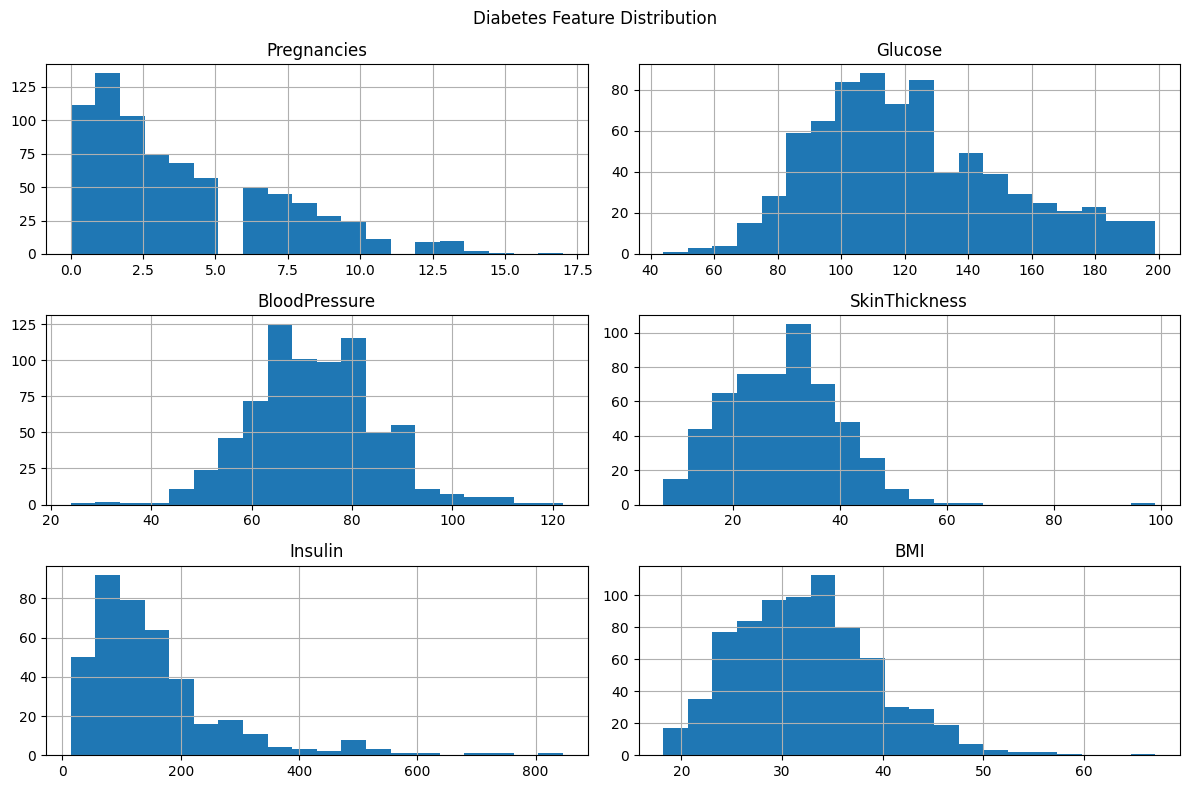

In [ ]:
import matplotlib.pyplot as plt

diabetes[diabetes_input_columns].hist(
    bins=20,
    figsize=(12, 8)
)

plt.suptitle("Diabetes Feature Distribution")
plt.tight_layout()
plt.show()

In [ ]:
diabetes[diabetes_input_columns].skew()

,0
Pregnancies,0.901674
Glucose,0.530989
BloodPressure,0.134153
SkinThickness,0.690619
Insulin,2.166464
BMI,0.593970


In [ ]:
for column in diabetes_input_columns:
  skew_value = diabetes[column].skew()

  if -0.5 <= skew_value <= 0.5:
    print(column, "-> Use mean")
  else:
    print(column, "-> Use median")

Pregnancies -> Use median
Glucose -> Use median
BloodPressure -> Use mean
SkinThickness -> Use median
Insulin -> Use median
BMI -> Use median


In [ ]:
diabetes["Glucose"] = diabetes["Glucose"].fillna(
    diabetes["Glucose"].median
)
diabetes["BloodPressure"] = diabetes["BloodPressure"].fillna(
    diabetes["BloodPressure"].mean()
)

In [ ]:
diabetes.isnull().sum()


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
diabetes["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


<function matplotlib.pyplot.show(close=None, block=None)>

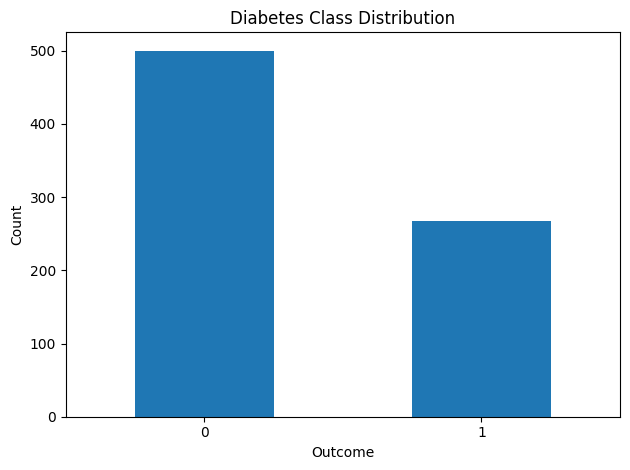

In [ ]:
diabetes["Outcome"].value_counts().sort_index().plot(
    kind="bar"
)
plt.title("Diabetes Class Distribution")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show

In [ ]:
from sklearn.model_selection import train_test_split

x_diabetes = diabetes[diabetes_input_columns]
y_diabetes = diabetes[diabetes_target_column]

x_train_diabetes, x_test_diabetes, y_train_diabetes, y_test_diabetes = train_test_split(
    x_diabetes,
    y_diabetes,
    test_size=0.20,
    random_state=42,
    stratify=y_diabetes
)

print("Training rows:", x_train_diabetes.shape[0])
print("Testing rows:", x_test_diabetes.shape[0])

Training rows: 614
Testing rows: 154


In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42
)

In [ ]:
# 1. Reload or fix Glucose by replacing the method object with actual numeric values
diabetes = pd.read_csv(diabetes_path, names=diabetes_columns)
diabetes[invalid_zero_columns] = diabetes[invalid_zero_columns].replace(0, np.nan)

# 2. Re-split the clean data
x_diabetes = diabetes[diabetes_input_columns]
y_diabetes = diabetes[diabetes_target_column]

x_train_diabetes, x_test_diabetes, y_train_diabetes, y_test_diabetes = train_test_split(
    x_diabetes,
    y_diabetes,
    test_size=0.20,
    random_state=42,
    stratify=y_diabetes
)

# 3. Impute missing values using training set stats (median for skewed columns, mean for BloodPressure)
median_cols = ["Pregnancies", "Glucose", "SkinThickness", "Insulin", "BMI"]
for col in median_cols:
    med = x_train_diabetes[col].median()
    x_train_diabetes[col] = x_train_diabetes[col].fillna(med)
    x_test_diabetes[col] = x_test_diabetes[col].fillna(med)

bp_mean = x_train_diabetes["BloodPressure"].mean()
x_train_diabetes["BloodPressure"] = x_train_diabetes["BloodPressure"].fillna(bp_mean)
x_test_diabetes["BloodPressure"] = x_test_diabetes["BloodPressure"].fillna(bp_mean)

# 4. Fit the model
decision_tree_model.fit(x_train_diabetes, y_train_diabetes)

DecisionTreeClassifier(class_weight='balanced', max_depth=4, random_state=42)

In [ ]:
diabetes_predictions = decision_tree_model.predict(
    x_test_diabetes
)

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

accuracy = accuracy_score(
    y_test_diabetes,
    diabetes_predictions
)
print("Accuracy:, accuracy")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_diabetes,
        diabetes_predictions
    )
)

Accuracy:, accuracy

Confusion Matrix:
[[76 24]
 [15 39]]


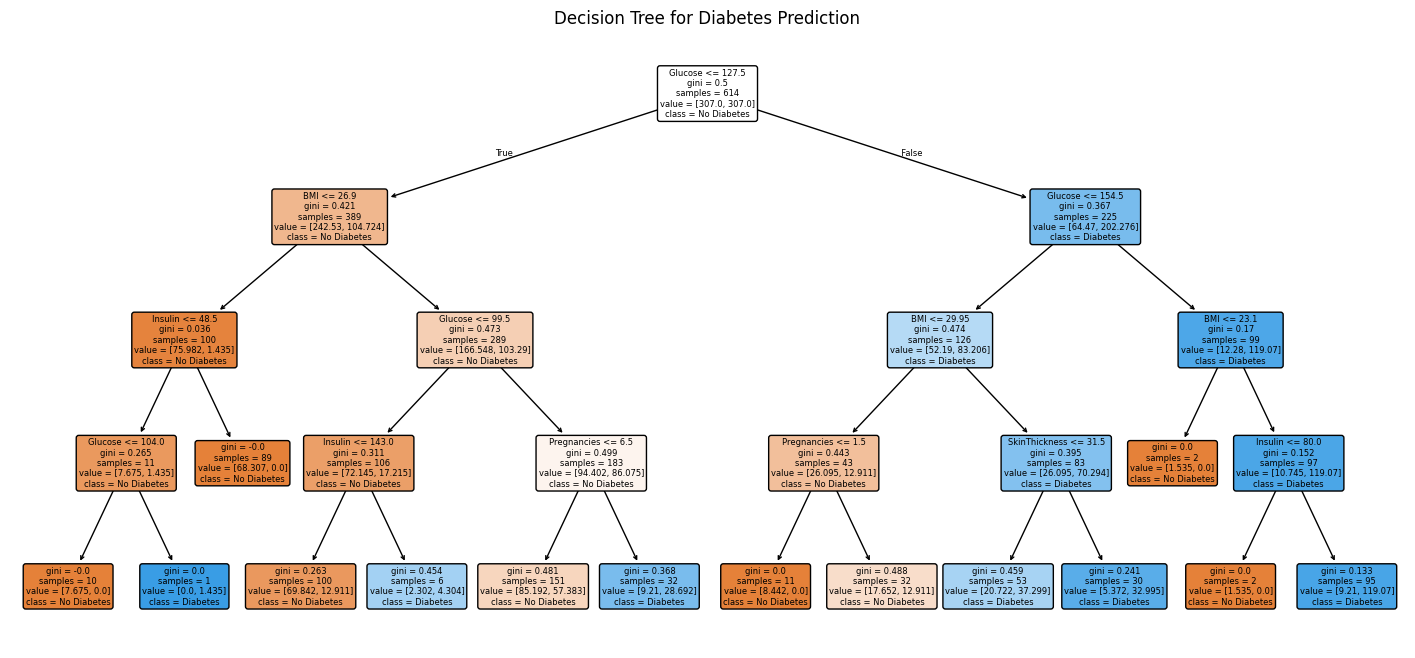

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    decision_tree_model,
    feature_names=x_diabetes.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree for Diabetes Prediction")
plt.show()